# Lab 1: Brilliant by Chance

*Financial Engineering and the Evidence*, Chapter 1.

**Claim on trial:** a strategy with an impressive backtest has skill.

You will build 1,000 market-timing strategies that switch between stocks and Treasury bills **at random**. Every one has zero skill by construction. You will backtest them on the first half of nearly a century of U.S. market data, pick the winners, and see what happens to them afterward.

This notebook walks through the lab step by step. `python lab01.py` runs the same analysis in one go and writes a full report.

In [1]:
from pathlib import Path
from IPython.display import Image, display
import lab01

SOURCE = "french"   # "french" downloads real data; "sim" uses fake data to test the code
DATA_FILE = None    # or the path of a French library zip you downloaded yourself
OUT = Path("report")
OUT.mkdir(exist_ok=True)

mkt = lab01.load_market(SOURCE, DATA_FILE)
SIMULATED = mkt.attrs.get("simulated", False)
print(f"{len(mkt)} months, {mkt.index[0]} to {mkt.index[-1]}", "(SIMULATED)" if SIMULATED else "")
mkt.tail()

1203 months, 1926-07 to 2026-09 


,mkt_rf,rf
date,,
2026-05,0.0491,0.0031
2026-06,-0.0107,0.0029
2026-07,-0.0061,0.0033
2026-08,0.0256,0.0029
2026-09,-0.0107,0.0031


## Part A: Signal and noise

How good is the stock market itself, by the Sharpe ratio, and how much does a 10-year record vary?

Market excess return 8.3% a year, volatility 18.4%
Sharpe ratio 0.45, t = 4.54 over 100 years
10-year Sharpe ratios ranged from -0.28 to 1.58


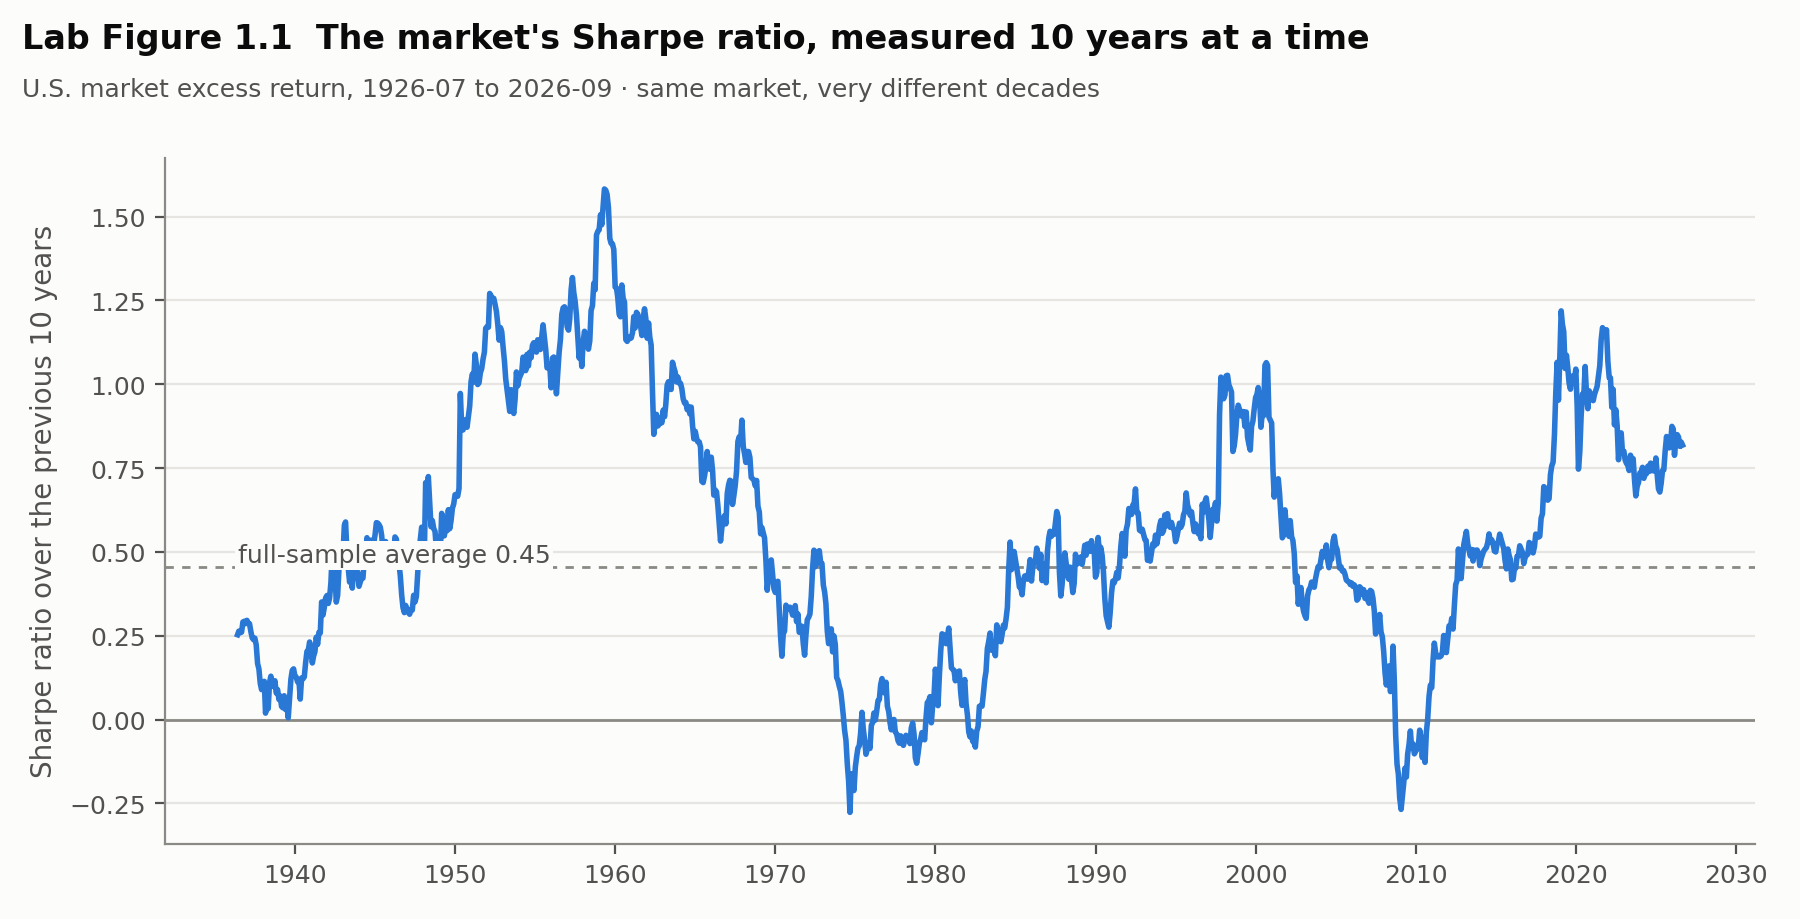

,true_sharpe,years_needed
0,0.25,61.465600
1,0.50,15.366400
2,0.75,6.829511
3,1.00,3.841600
4,1.50,1.707378


In [2]:
a = lab01.part_a(mkt, window_years=10)
print(f"Market excess return {a['mean_excess_ann']:.1%} a year, volatility {a['vol_ann']:.1%}")
print(f"Sharpe ratio {a['sharpe']:.2f}, t = {a['t_stat']:.2f} over {a['years']:.0f} years")
print(f"10-year Sharpe ratios ranged from {a['rolling_min']:.2f} to {a['rolling_max']:.2f}")
lab01.fig_rolling(a, OUT, SIMULATED)
display(Image(OUT / "fig1_1_rolling_sharpe.png"))
a["detect"]

## Part B: 1,000 strategies with zero skill

**Predict before you run.** Out of 1,000 strategies with no skill, how many do you expect to pass the usual significance test (t > 1.96) in the backtest? How large will the best t-statistic be? Write your guesses down.

Backtest: 1926-07 to 1976-07
57 strategies pass t > 1.96 (about 25 expected by luck)
Best backtest: alpha +4.28% a year, t = 3.08


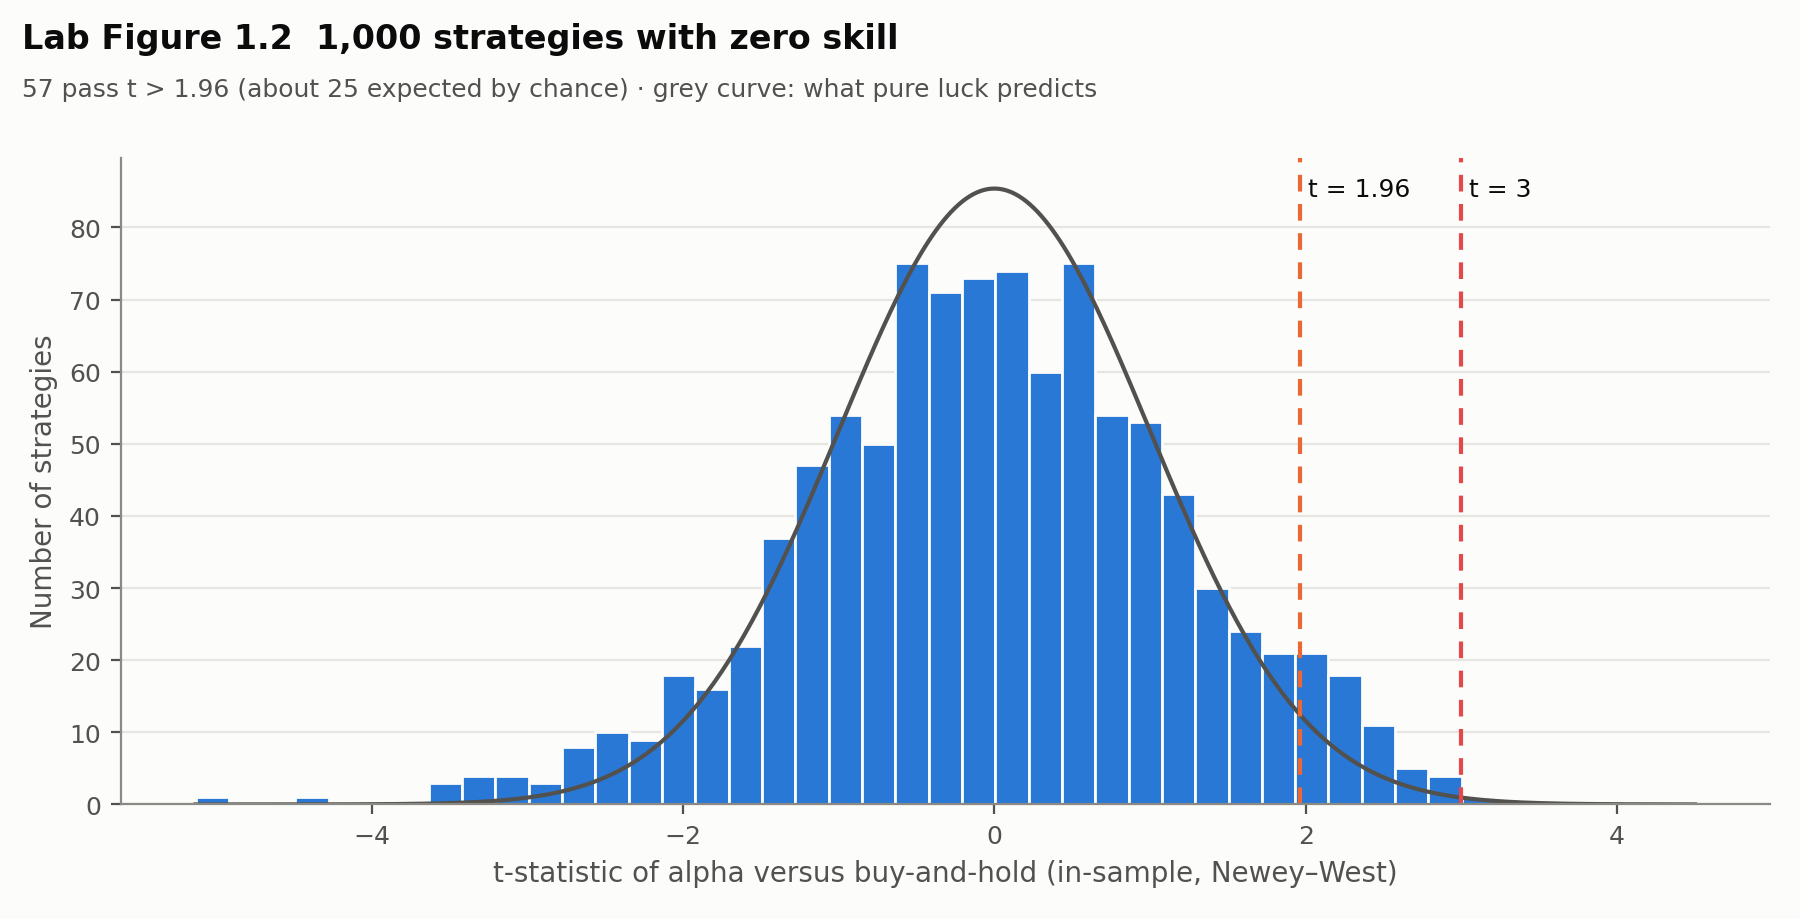

In [3]:
b = lab01.part_b(mkt, n_strategies=1000, seed=2026)
s = lab01.summarize_b(b)
print(f"Backtest: {s['in_sample']['start']} to {s['in_sample']['end']}")
print(f"{s['count_t_above_1_96']} strategies pass t > 1.96 (about {s['expected_count_t_above_1_96']:.0f} expected by luck)")
print(f"Best backtest: alpha {s['best_alpha_in_sample_pct']:+.2f}% a year, t = {s['best_t_in_sample']:.2f}")
lab01.fig_histogram(b, s, OUT, SIMULATED)
display(Image(OUT / "fig1_2_t_histogram.png"))

Now follow the winners into the second half of the sample, the period an investor who picked them would actually have lived through.

After selection: 1976-08 to 2026-09
Best strategy afterward: alpha +0.84% a year, t = 0.71
Correlation between backtest t and later t: -0.05


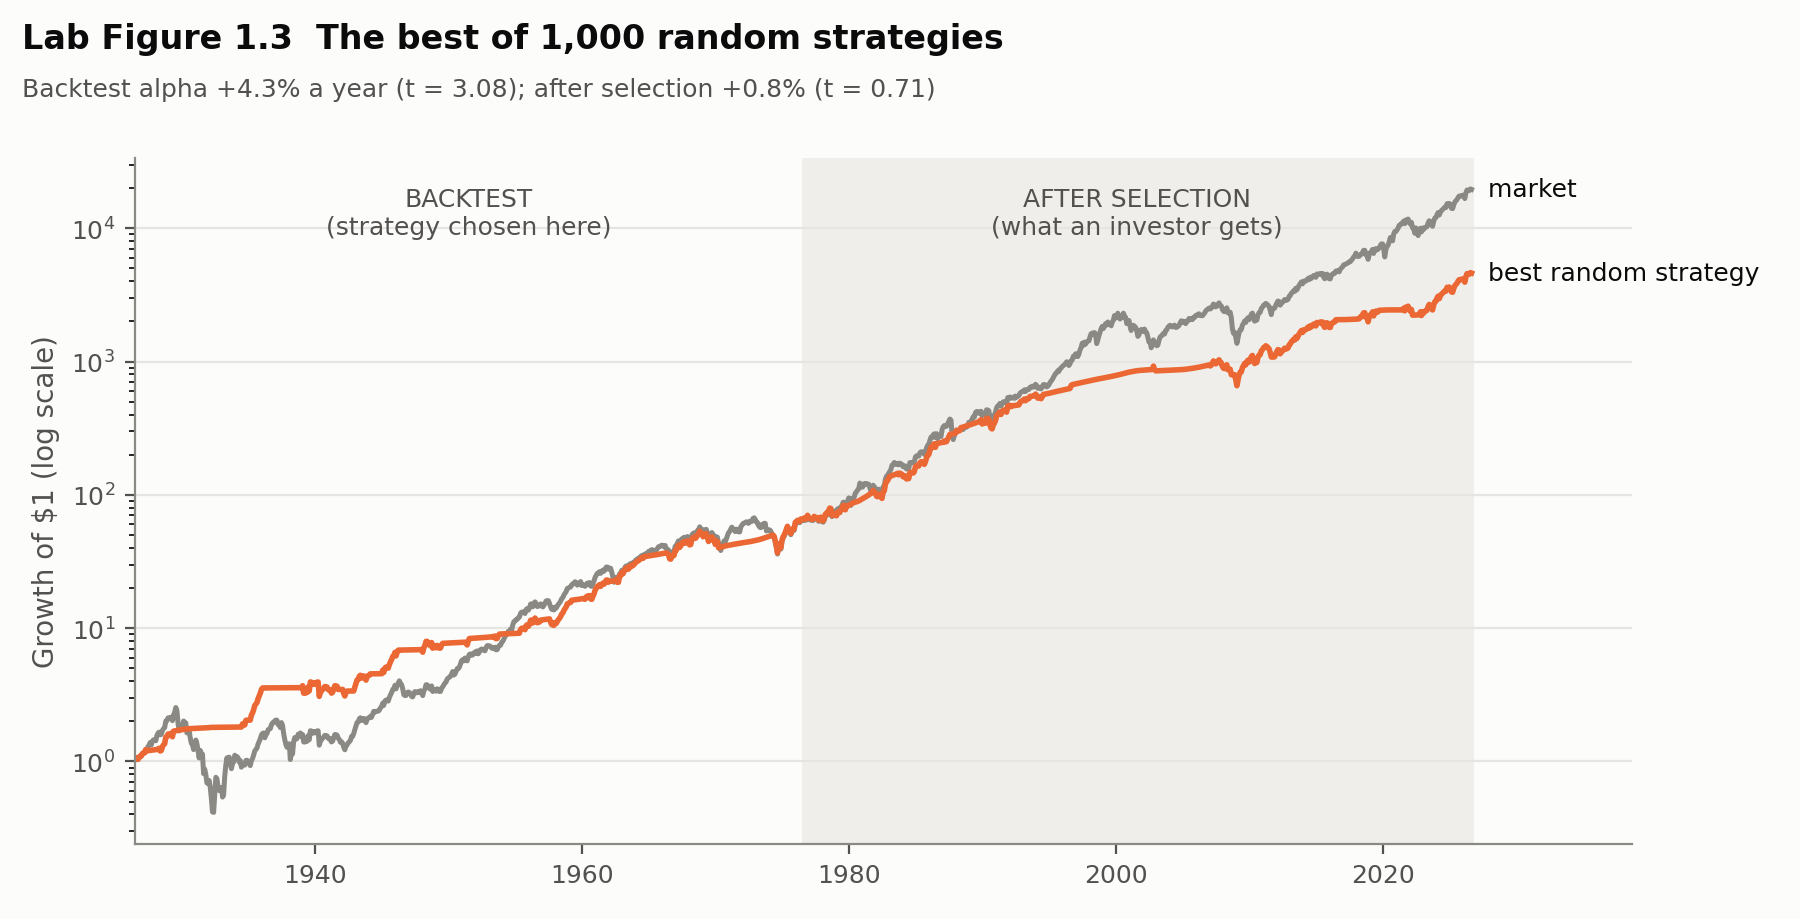

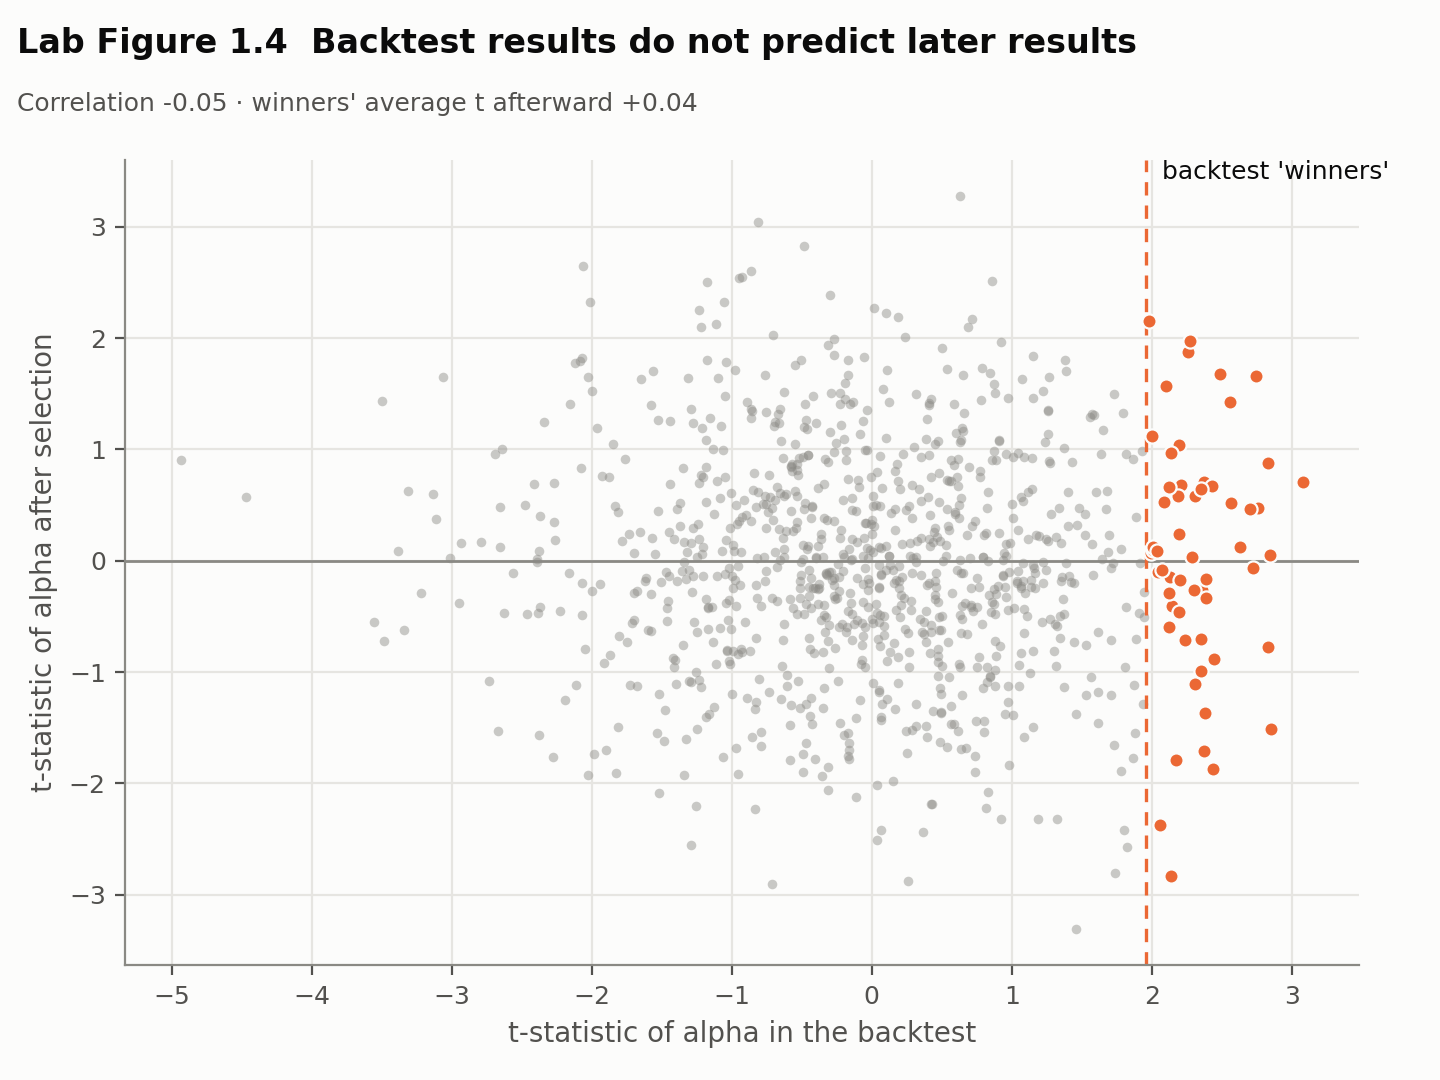

,strategy,alpha_in_sample_pct,t_in_sample,alpha_out_of_sample_pct,t_out_of_sample
0,698,4.28,3.08,0.84,0.71
1,479,3.86,2.85,-1.76,-1.51
2,327,4.46,2.85,0.07,0.05
3,813,4.09,2.83,1.09,0.88
4,643,3.67,2.83,-1.00,-0.78
5,93,4.25,2.76,0.60,0.47
6,756,3.89,2.74,2.00,1.66
7,575,3.82,2.72,-0.08,-0.06
8,242,4.24,2.70,0.55,0.47
9,357,4.15,2.63,0.15,0.13


In [4]:
print(f"After selection: {s['out_of_sample']['start']} to {s['out_of_sample']['end']}")
print(f"Best strategy afterward: alpha {s['best_alpha_out_of_sample_pct']:+.2f}% a year, t = {s['best_t_out_of_sample']:.2f}")
print(f"Correlation between backtest t and later t: {s['correlation_t_in_vs_out']:+.2f}")
lab01.fig_best(mkt, b, s, OUT, SIMULATED)
lab01.fig_scatter(b, s, OUT, SIMULATED)
display(Image(OUT / "fig1_3_best_strategy.png"))
display(Image(OUT / "fig1_4_in_vs_out.png"))
s["top10"].round(2)

## Part C: The cost of searching

How does the best backtest improve as you try more strategies?

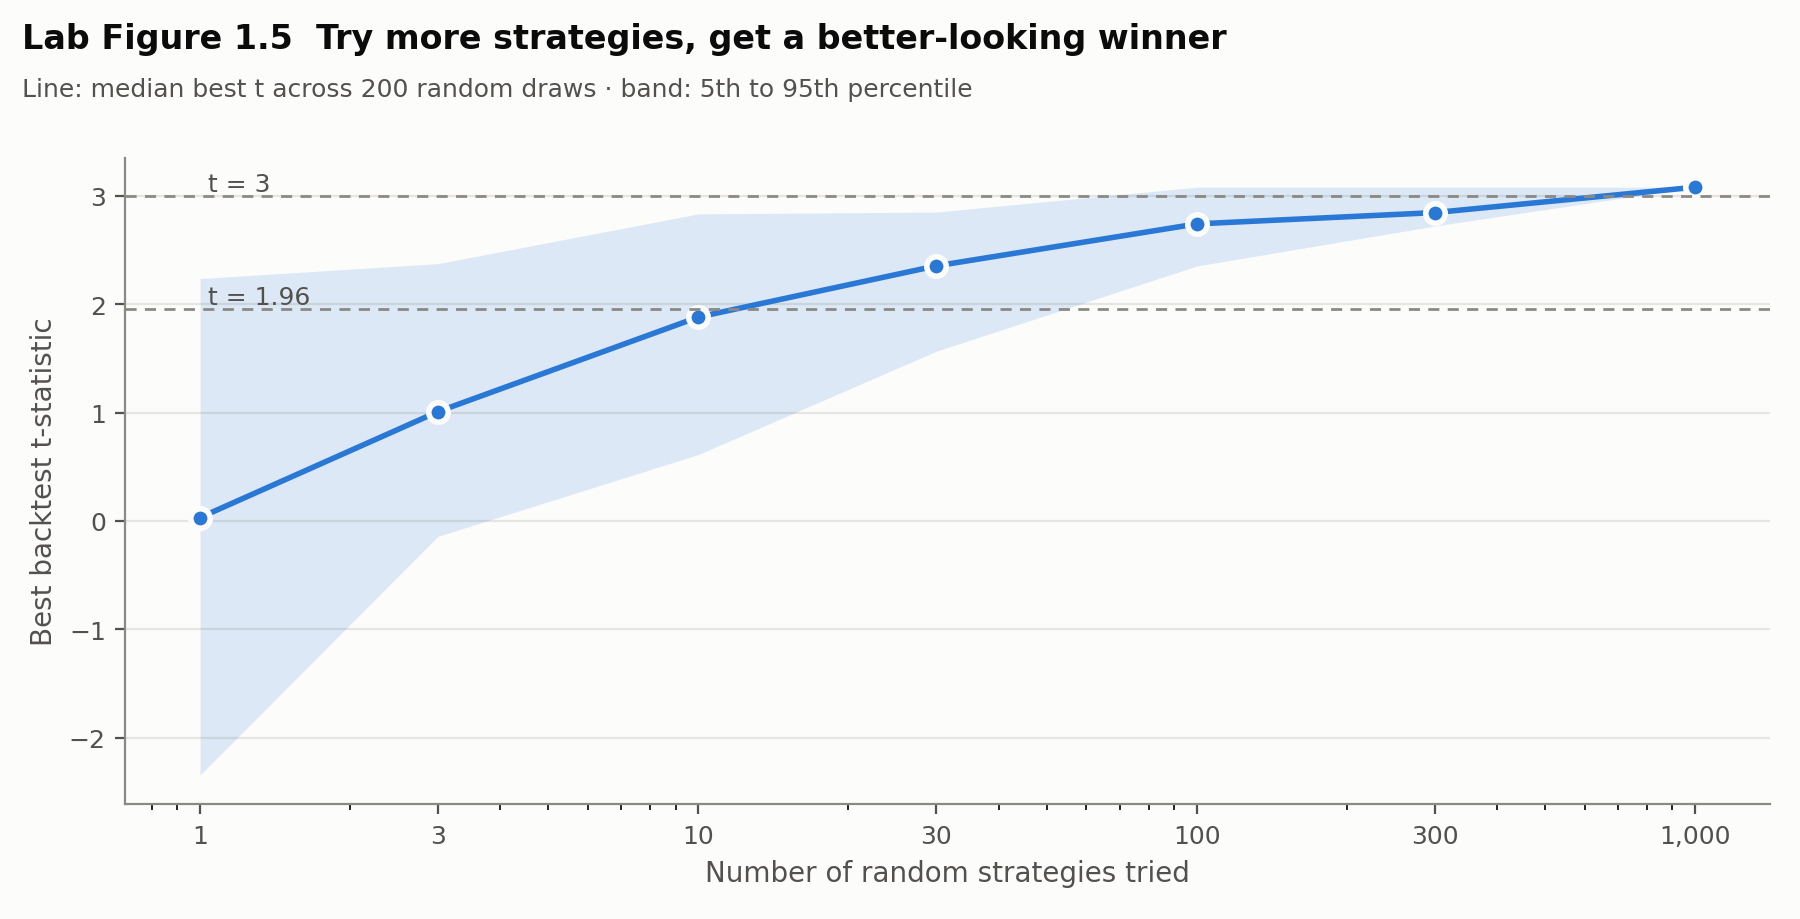

,strategies_tried,best_t_median,best_t_p05,best_t_p95,approx_sqrt_2lnk
0,1,0.03,-2.35,2.24,0.00
1,3,1.01,-0.14,2.37,1.48
2,10,1.88,0.61,2.83,2.15
3,30,2.35,1.57,2.85,2.61
4,100,2.74,2.35,3.08,3.03
5,300,2.85,2.72,3.08,3.38
6,1000,3.08,3.08,3.08,3.72


In [5]:
c = lab01.part_c(b)
lab01.fig_search(c, OUT, SIMULATED)
display(Image(OUT / "fig1_5_search_cost.png"))
c.round(2)

## Your verdict

1. Does an impressive backtest, on its own, show skill? Answer in two or three sentences using your numbers.
2. Name one piece of information you would ask for before believing a backtest.
3. Change `seed` in Part B and re-run. How much does the number of "significant" strategies change, and why might it differ from the 25 expected?
4. Set `n_strategies=10000`. What happens to the best backtest t-statistic?